In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("loan_approval_data.csv")

In [3]:
df.head()
df.info()
df.isnull().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [4]:
# Handle Missing Values

In [5]:
categorical_cols = df.select_dtypes(include = "object").columns
numerical_cols = df.select_dtypes(include = ["number"]).columns

In [6]:
from sklearn.impute import SimpleImputer
num_imp = SimpleImputer(strategy = "mean")
df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])

cat_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])

In [7]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [8]:
 # EDA - Explorartory Data Analysis

Text(0.5, 1.0, 'Is Loan Approved')

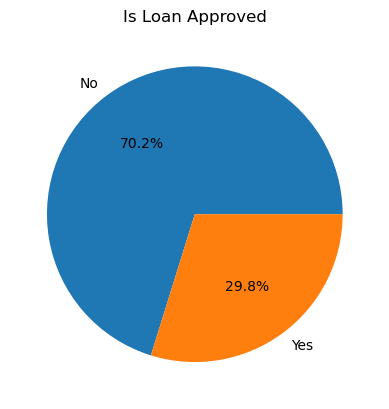

In [9]:
#how balanced Our Classes Are ?
classes_count = df["Loan_Approved"].value_counts()
plt.pie(classes_count , labels=["No" , "Yes"] , autopct = "%1.1f%%")
plt.title("Is Loan Approved")

[Text(0, 0, '422'),
 Text(0, 0, '202'),
 Text(0, 0, '144'),
 Text(0, 0, '135'),
 Text(0, 0, '97')]

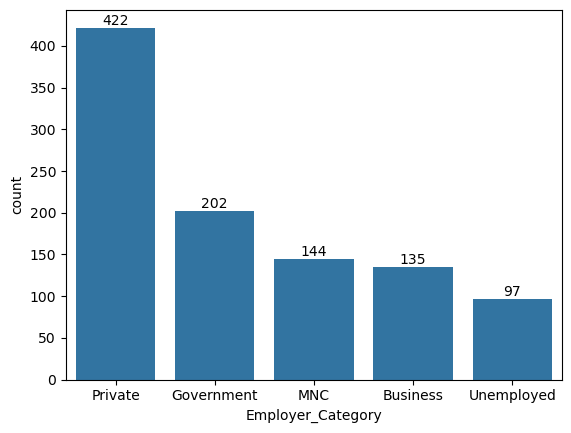

In [10]:
# Analyze categories
#gender_cnt = df["Gender"].value_counts()
#ax = sns.barplot(gender_cnt)
#ax.bar_label(ax.containers[0])

# education_cnt = df["Education_Level"].value_counts()
# ax = sns.barplot(education_cnt)
# ax.bar_label(ax.containers[0])

# prp_cnt = df["Property_Area"].value_counts()
# ax = sns.barplot(prp_cnt)
# ax.bar_label(ax.containers[0])

emp_cnt = df["Employer_Category"].value_counts()
ax = sns.barplot(emp_cnt)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

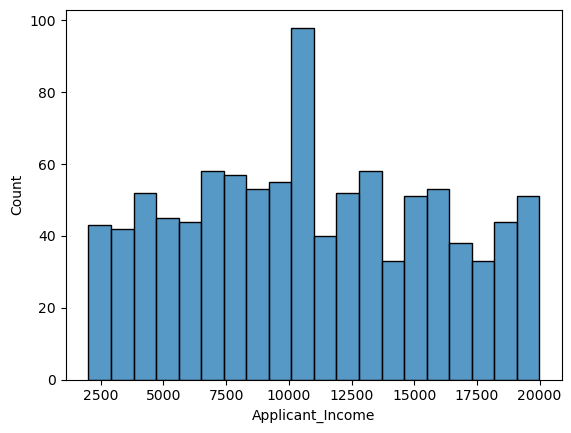

In [11]:
sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

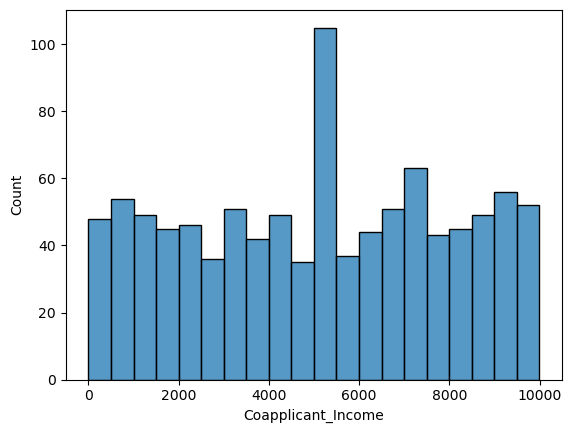

In [12]:
sns.histplot(
    data = df,
    x = "Coapplicant_Income",
    bins = 20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

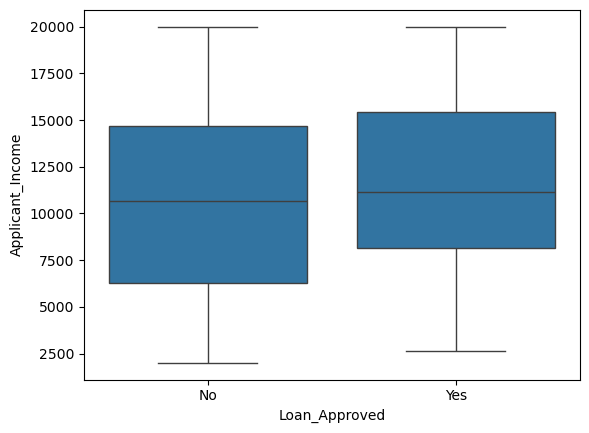

In [13]:
# outliers - box plots
sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Applicant_Income"
)


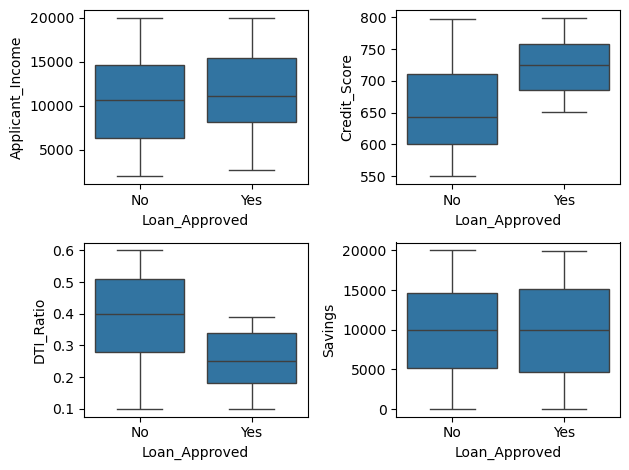

In [14]:
fig , axes = plt.subplots(2,2)

sns.boxplot(ax=axes[0,0],data=df,x="Loan_Approved" , y="Applicant_Income")
sns.boxplot(ax=axes[0,1],data=df,x="Loan_Approved" , y="Credit_Score")
sns.boxplot(ax=axes[1,0],data=df,x="Loan_Approved" , y="DTI_Ratio")
sns.boxplot(ax=axes[1,1],data=df,x="Loan_Approved" , y="Savings")

plt.tight_layout()


<Axes: xlabel='Credit_Score', ylabel='Count'>

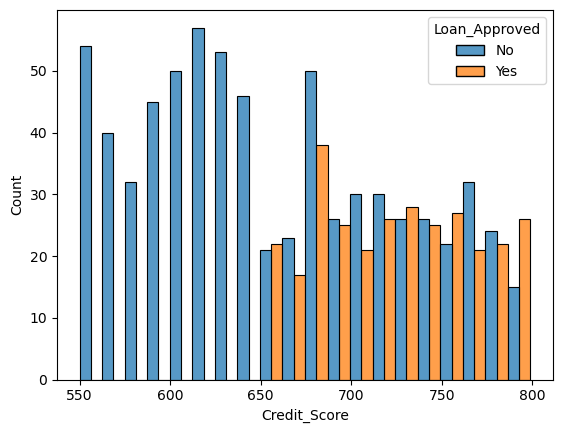

In [15]:
sns.histplot(
    data = df,
    x = "Credit_Score",
    hue = "Loan_Approved",
    bins = 20,
    multiple = "dodge"
)

In [16]:
#Remove Applicanr ID
df = df.drop("Applicant_ID" , axis =1)

In [17]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


# Encoding


In [18]:
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    1000 non-null   float64
 1   Coapplicant_Income  1000 non-null   float64
 2   Employment_Status   1000 non-null   object 
 3   Age                 1000 non-null   float64
 4   Marital_Status      1000 non-null   object 
 5   Dependents          1000 non-null   float64
 6   Credit_Score        1000 non-null   float64
 7   Existing_Loans      1000 non-null   float64
 8   DTI_Ratio           1000 non-null   float64
 9   Savings             1000 non-null   float64
 10  Collateral_Value    1000 non-null   float64
 11  Loan_Amount         1000 non-null   float64
 12  Loan_Term           1000 non-null   float64
 13  Loan_Purpose        1000 non-null   object 
 14  Property_Area       1000 non-null   object 
 15  Education_Level     1000 non-null   object 
 16  Gender 

In [19]:
from sklearn.preprocessing import LabelEncoder , OneHotEncoder
le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])

In [20]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [21]:
cols = ["Employment_Status" , "Marital_Status" , "Gender" , "Loan_Purpose" , "Property_Area" ,"Employer_Category"]

ohe = OneHotEncoder(drop="first" , sparse_output=False , handle_unknown = "ignore")

encoded = ohe.fit_transform(df[cols])

encoded_df=pd.DataFrame(encoded , columns =ohe.get_feature_names_out(cols) , index = df.index )

df = pd.concat([df.drop(columns = cols) , encoded_df] , axis = 1)

In [22]:
df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


# Correlation Heatmap

In [23]:
num_cols = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()

<Axes: >

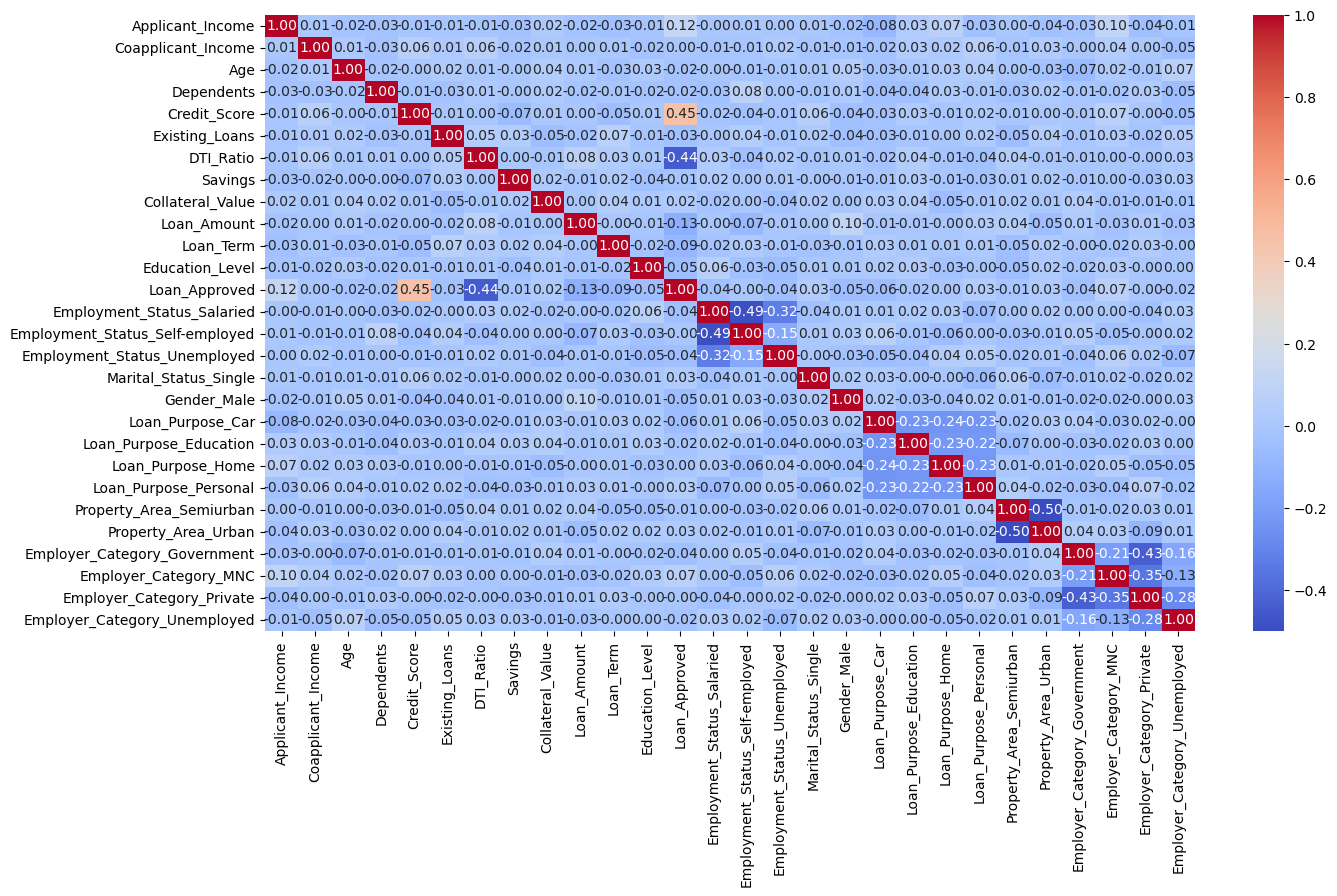

In [24]:
num_cols.corr()["Loan_Approved"].sort_values(ascending=False)
plt.figure(figsize=(15,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

# Train Test Split + Feature Scaling

In [25]:
X =df.drop("Loan_Approved" , axis=1)
y = df["Loan_Approved"]

In [26]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Loan_Approved, dtype: int64

In [27]:
X_train , X_test , y_train , y_test = train_test_split(
    X , y ,test_size=0.2 , random_state=42
)

In [28]:
X_test.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
521,13023.0,6675.0,53.000000,3.0,628.0,3.0,0.347263,10051.000000,26309.0,22947.000000,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
737,15917.0,6787.0,42.000000,0.0,588.0,4.0,0.410000,922.000000,13476.0,20522.825263,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
740,7560.0,3530.0,52.000000,3.0,606.0,0.0,0.580000,9940.452632,21795.0,5876.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
660,19022.0,574.0,59.000000,0.0,725.0,4.0,0.410000,1463.000000,44498.0,8433.000000,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
411,4967.0,5797.0,39.971579,3.0,697.0,4.0,0.580000,1095.000000,3017.0,33926.000000,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
X_train_scaled

array([[-1.01234556e+00,  1.02716377e+00, -8.22511453e-01, ...,
        -4.13887756e-01, -8.59726954e-01, -3.07231582e-01],
       [-1.23639141e+00, -1.59187898e+00,  9.15886794e-01, ...,
        -4.13887756e-01, -8.59726954e-01, -3.07231582e-01],
       [-1.15862490e-02,  1.33606578e+00, -3.65038230e-01, ...,
        -4.13887756e-01,  1.16316000e+00, -3.07231582e-01],
       ...,
       [-2.27277589e-01,  3.50089621e-01, -8.22511453e-01, ...,
        -4.13887756e-01,  1.16316000e+00, -3.07231582e-01],
       [ 1.12970221e+00, -4.64700438e-01,  1.19037073e+00, ...,
        -4.13887756e-01, -8.59726954e-01, -3.07231582e-01],
       [-1.75526629e+00,  1.43417276e-02,  9.40348249e-04, ...,
         2.41611400e+00, -8.59726954e-01, -3.07231582e-01]],
      shape=(800, 27))

# Train & Evaluate The Models

In [47]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score , confusion_matrix , precision_score , recall_score , f1_score

log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train )
y_pred = log_model.predict(X_test_scaled)

#Evaluation
print("Logistic_Model:")
print("Precision_Score : " , precision_score(y_test , y_pred))
print("Accuracy_Score : " , accuracy_score(y_test , y_pred))
print("recall_Score : " , recall_score(y_test , y_pred))
print("f1_Score : " , f1_score(y_test , y_pred))
print("confusion_matrix : " , confusion_matrix(y_test , y_pred))

Logistic_Model:
Precision_Score :  0.7833333333333333
Accuracy_Score :  0.865
recall_Score :  0.7704918032786885
f1_Score :  0.7768595041322314
confusion_matrix :  [[126  13]
 [ 14  47]]


In [48]:
# KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score , confusion_matrix , precision_score , recall_score , f1_score

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train )
y_pred = knn_model.predict(X_test_scaled)

#Evaluation
print("KNN Model:")
print("Precision_Score : " , precision_score(y_test , y_pred))
print("Accuracy_Score : " , accuracy_score(y_test , y_pred))
print("recall_Score : " , recall_score(y_test , y_pred))
print("f1_Score : " , f1_score(y_test , y_pred))
print("confusion_matrix : " , confusion_matrix(y_test , y_pred))

KNN Model:
Precision_Score :  0.6274509803921569
Accuracy_Score :  0.76
recall_Score :  0.5245901639344263
f1_Score :  0.5714285714285714
confusion_matrix :  [[120  19]
 [ 29  32]]


In [51]:
# Naive Bayes maodel
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score , confusion_matrix , precision_score , recall_score , f1_score

gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train )
y_pred = gnb_model.predict(X_test_scaled)

#Evaluation
print("Naive Bayes :")
print("Precision_Score : " , precision_score(y_test , y_pred))
print("Accuracy_Score : " , accuracy_score(y_test , y_pred))
print("recall_Score : " , recall_score(y_test , y_pred))
print("f1_Score : " , f1_score(y_test , y_pred))
print("confusion_matrix : " , confusion_matrix(y_test , y_pred))

Naive Bayes :
Precision_Score :  0.8035714285714286
Accuracy_Score :  0.865
recall_Score :  0.7377049180327869
f1_Score :  0.7692307692307693
confusion_matrix :  [[128  11]
 [ 16  45]]


# Based ON Precision_Score Best model is => Naive_Bayes

# Feature Engineering

In [59]:
#ADD or Trandform The features
df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2
df["Credit_Score_sq"] = df["Credit_Score"] ** 2
#df["Applicant_Income"] = np.log1p(df["Applicant_Income"])

X = df.drop(columns=["Loan_Approved" , "DTI_Ratio" , "Credit_Score"])
y = df["Loan_Approved"]

# Trian_test_split
X_train , X_test , y_train , y_test = train_test_split(
    X , y ,test_size=0.2 , random_state=42
)

#Scaling:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [60]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score , confusion_matrix , precision_score , recall_score , f1_score

log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train )
y_pred = log_model.predict(X_test_scaled)

#Evaluation
print("Logistic_Model:")
print("Precision_Score : " , precision_score(y_test , y_pred))
print("Accuracy_Score : " , accuracy_score(y_test , y_pred))
print("recall_Score : " , recall_score(y_test , y_pred))
print("f1_Score : " , f1_score(y_test , y_pred))
print("confusion_matrix : " , confusion_matrix(y_test , y_pred))

Logistic_Model:
Precision_Score :  0.7903225806451613
Accuracy_Score :  0.875
recall_Score :  0.8032786885245902
f1_Score :  0.7967479674796748
confusion_matrix :  [[126  13]
 [ 12  49]]


In [61]:
# KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score , confusion_matrix , precision_score , recall_score , f1_score

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train )
y_pred = knn_model.predict(X_test_scaled)

#Evaluation
print("KNN Model:")
print("Precision_Score : " , precision_score(y_test , y_pred))
print("Accuracy_Score : " , accuracy_score(y_test , y_pred))
print("recall_Score : " , recall_score(y_test , y_pred))
print("f1_Score : " , f1_score(y_test , y_pred))
print("confusion_matrix : " , confusion_matrix(y_test , y_pred))

KNN Model:
Precision_Score :  0.6226415094339622
Accuracy_Score :  0.76
recall_Score :  0.5409836065573771
f1_Score :  0.5789473684210527
confusion_matrix :  [[119  20]
 [ 28  33]]


In [62]:
# Naive Bayes maodel
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score , confusion_matrix , precision_score , recall_score , f1_score

gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train )
y_pred = gnb_model.predict(X_test_scaled)

#Evaluation
print("Naive Bayes :")
print("Precision_Score : " , precision_score(y_test , y_pred))
print("Accuracy_Score : " , accuracy_score(y_test , y_pred))
print("recall_Score : " , recall_score(y_test , y_pred))
print("f1_Score : " , f1_score(y_test , y_pred))
print("confusion_matrix : " , confusion_matrix(y_test , y_pred))

Naive Bayes :
Precision_Score :  0.8
Accuracy_Score :  0.86
recall_Score :  0.7213114754098361
f1_Score :  0.7586206896551724
confusion_matrix :  [[128  11]
 [ 17  44]]
